# IE 7615 Project — Milestone 2: Multi-Object Detection and Location (YOLOv8s)

Given one image that contains many objects, the model must report **every object's ID and its location (bounding box)**.

### Version 2: what changed and why

| # | Change | Reason (instructors' Milestone 2 clarifications) |
|---|---|---|
| 1 | Multi-object images are now **grids of 224 × 224 photos placed side by side**: 2×2, 3×3, 4×4, 5×4 and 5×5 (up to 1120 × 1120). Version 1 pasted 2–5 resized photos onto a 640 × 640 background. | §2 Grid images, and the report must state the grid sizes used |
| 2 | Each box now surrounds **the object inside the photo**, created by two open-vocabulary detectors (**YOLO-World** and **Grounding DINO**) that check each other. Version 1 used the whole pasted photo as the box, which is why mAP@0.5 and mAP@0.5:0.95 were identical. | §3 Labelling: create boxes, check a sample, report photos left out |
| 3 | **Exact duplicate photos are removed before the split.** Version 1 had 13 groups of identical photos in different splits (5 test photos had a copy in train). | §4 and §5: no copy in more than one split |
| 4 | **OBJ054_017 is excluded.** | §4 |
| 5 | Every photo is resized to 224 × 224 (fixes the OBJ003 photo) and its EXIF rotation is applied. | §4 |
| 6 | Background-only photos (`_bg_`) are **no longer used**: grids have no background. This also removes the 5 OBJ065 `_bg_` files, which are copies of OBJ065 object photos. | §2 |
| 7 | `imgsz=1120`, `batch=8`, checkpoints saved to Google Drive, training resumes after a disconnect. | §2 tip |
| 8 | Photos left out per Object ID (and why), label check figures, metrics per grid size and per Object ID, training curves, confusion matrix, more example detections and an error analysis. | §3, §4, §5 report items |
| 9 | Paths point to our own Google Drive. Nothing is written to the shared dataset folder, and only this notebook goes to GitHub. | §5 |

### How to run (Google Colab)
1. `database.zip` must be at `My Drive/NEU/IE7615 Deep Learning for AI/Project1/database.zip` (same file as Milestone 1).
2. *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
3. Results go to `My Drive/NEU/IE7615 Deep Learning for AI/Project1/week2_results/`. If Colab disconnects, *Run all* again:
   the box labels are reloaded from Drive and training continues from the last epoch.

**Expected run time on a T4: about 1–1.5 hours** (labelling 15–25 min, grids ~5 min, training 35–55 min, evaluation ~5 min).

## 1. Mount Google Drive

> **Note:** unchanged from version 1. The `if` lets the same code also run outside Colab for a quick local test.

In [1]:
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


## 2. Paths and settings

> **Note (changed):** the paths now point to **our** Google Drive: `My Drive/NEU/IE7615 Deep Learning for AI/Project1`,
> the same folder as Milestone 1. `database.zip` contains `database/images_OBJxxx/`, so it is unzipped to
> `/content/database` (local disk: much faster than reading from Drive).
> Outputs (labels, figures, model weights) are saved to `week2_results/` in our Drive. Grid images are built on the
> Colab disk and a zip copy is kept in our Drive. Nothing is uploaded to the shared class folder.
>
> All settings are in this one cell: grid sizes, number of grid images, model settings.
> `QUICK=1` is only for a local smoke test (3 objects, tiny models, 1 epoch). It is off on Colab.

In [2]:
import os, re, sys, json, time, shutil, zipfile, hashlib
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("QUICK") == "1"

if IN_COLAB:
    DRIVE_DIR = "/content/drive/MyDrive/NEU/IE7615 Deep Learning for AI/Project1"   # our Drive (same as Milestone 1)
    DATA_DIR = "/content/database"
    WORK_DIR = "/content"
    OUT_DIR = f"{DRIVE_DIR}/week2_results"
    if not os.path.isdir(DATA_DIR):
        with zipfile.ZipFile(f"{DRIVE_DIR}/database.zip") as z:
            z.extractall("/content")
else:   # local smoke test
    DATA_DIR = os.environ.get("DATA_DIR", "database")
    WORK_DIR = os.environ.get("WORK_DIR", "week2_work")
    OUT_DIR = os.environ.get("OUT_DIR", "week2_results")

PHOTO_DIR = f"{WORK_DIR}/photos224"   # cleaned 224 x 224 copies of the single photos
YOLO_DIR = f"{WORK_DIR}/yolo_data"    # grid images + YOLO labels
for d in [OUT_DIR, f"{OUT_DIR}/labels", f"{OUT_DIR}/figures", PHOTO_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
FOCUS_ID = "OBJ036"                   # our own object: checked by hand and highlighted in the results
EXCLUDE = {"OBJ054_017"}              # instructor note: not a photo of the object
TILE = 224                            # every photo becomes one 224 x 224 grid cell
GRID_SIZES = [(2, 2), (3, 3), (4, 4), (5, 4), (5, 5)]   # (columns, rows): 448x448, 672x672, 896x896, 1120x896, 1120x1120
N_GRIDS = {"train": 800, "val": 150, "test": 150}       # equal mix of the five grid sizes in every split
GRID_SEEDS = {"train": 1, "val": 2, "test": 3}          # one seed per split, as in version 1
IMGSZ, BATCH, EPOCHS, PATIENCE = 1120, 8, 50, 15        # instructor tip: imgsz close to the largest grid, batch=8 on Colab
CONF = 0.5                            # confidence threshold for the example detections (as in version 1)
YW_WEIGHTS = "yolov8x-worldv2.pt"     # labelling model 1
GD_MODEL, GD_SIZE = "IDEA-Research/grounding-dino-tiny", 640   # labelling model 2 and its input size
DET_WEIGHTS, RUN_NAME = "yolov8s.pt", "yolov8s_grid"
CLASS_IDS, PHOTOS_PER_CLASS = None, None   # None = all 73 Object IDs and all photos

if QUICK:
    CLASS_IDS, PHOTOS_PER_CLASS = ["OBJ001", "OBJ007", FOCUS_ID], 20
    GRID_SIZES, N_GRIDS = [(2, 2), (3, 2)], {"train": 8, "val": 4, "test": 4}
    YW_WEIGHTS, GD_SIZE, DET_WEIGHTS, RUN_NAME = "yolov8s-worldv2.pt", 320, "yolov8n.pt", "quick"
    IMGSZ, BATCH, EPOCHS, PATIENCE = 320, 4, 1, 1

TIMES, T_START = {}, time.time()
print("data:", DATA_DIR, "| outputs:", OUT_DIR)

data: /content/database | outputs: /content/drive/MyDrive/NEU/IE7615 Deep Learning for AI/Project1/week2_results


## 3. Install Ultralytics and check the GPU

> **Note (moved up):** Ultralytics is now installed before the labelling step, because YOLO-World (used to create
> the boxes in step 5) is part of Ultralytics.

In [3]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.2 MB/s eta 0:00:00


In [4]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"

GPU available: True
GPU name: Tesla T4


## 4. Single photos: clean, remove duplicates, split

> **Note (changed):**
> * Background-only photos (`_bg_`) are not used any more: grid images have no background.
> * `OBJ054_017` is excluded (instructor note: not a photo of the object).
> * Every photo is saved once as a clean 224 × 224 RGB copy with its **EXIF rotation applied**. Some phone photos
>   carry a rotation flag; YOLO (OpenCV) applies it but PIL does not, which would shift the boxes. Photos that are not
>   224 × 224 (one in OBJ003) are resized here.
> * **Exact duplicates are removed before the split** (pixel-identical photos). One copy is kept. If the same
>   photo appeared under two Object IDs, all copies would be dropped because the label would be ambiguous.
> * The split is the same as Milestone 1 (stratified 70 / 15 / 15, seed 42), now made **after** the duplicates are
>   removed. A check at the end confirms that no photo (or copy of it) is in more than one split.

In [5]:
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps, ImageEnhance

t0 = time.time()
IMG_RE = re.compile(r"\.jpe?g$", re.I)
BG_RE = re.compile(r"_bg_", re.I)

folders = sorted(d for d in os.listdir(DATA_DIR) if d.startswith("images_OBJ"))
if CLASS_IDS:
    folders = [d for d in folders if d.replace("images_", "") in CLASS_IDS]
class_names = [d.replace("images_", "") for d in folders]

rows, removed = [], []
for i, d in enumerate(folders):
    files = sorted(f for f in os.listdir(os.path.join(DATA_DIR, d)) if IMG_RE.search(f) and not BG_RE.search(f))
    for f in files[:PHOTOS_PER_CLASS]:
        stem = os.path.splitext(f)[0]
        if stem in EXCLUDE:
            removed.append((stem, class_names[i], "excluded: not a photo of the object (instructor note)"))
            continue
        im = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, d, f))).convert("RGB")
        digest = hashlib.md5(im.tobytes() + str(im.size).encode()).hexdigest()   # identical pixels -> identical hash
        size = im.size
        if size != (TILE, TILE):
            im = im.resize((TILE, TILE), Image.BICUBIC)
        im.save(f"{PHOTO_DIR}/{stem}.jpg", quality=95)
        rows.append(dict(stem=stem, label=i, obj_id=class_names[i], src=f"{d}/{f}", photo=f"{PHOTO_DIR}/{stem}.jpg",
                         orig_size=f"{size[0]}x{size[1]}", hash=digest))
photos = pd.DataFrame(rows)
assert photos.stem.is_unique

# exact duplicates: handled BEFORE splitting
keep = pd.Series(True, index=photos.index)
for _, g in photos.groupby("hash"):
    if len(g) == 1:
        continue
    if g.obj_id.nunique() > 1:
        drop, why = g.index, "same photo under several Object IDs: " + ", ".join(g.stem)
    else:
        drop, why = g.index[1:], f"exact duplicate of {g.stem.iloc[0]}"
    for k in drop:
        keep[k] = False
        removed.append((photos.stem[k], photos.obj_id[k], why))
photos = photos[keep].reset_index(drop=True)
removed = pd.DataFrame(removed, columns=["stem", "obj_id", "reason"])

# same split as Milestone 1 (stratified 70/15/15, seed 42), on the de-duplicated photos
idx_train, idx_tmp = train_test_split(photos.index.values, test_size=0.30, stratify=photos.label, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=photos.label.loc[idx_tmp], random_state=SEED)
photos["split"] = "train"
photos.loc[idx_val, "split"] = "val"
photos.loc[idx_test, "split"] = "test"

hashes = {s: set(photos.hash[photos.split == s]) for s in ["train", "val", "test"]}
assert not (hashes["train"] & hashes["val"] or hashes["train"] & hashes["test"] or hashes["val"] & hashes["test"])
print("check passed: no photo (or copy of it) is in more than one split")

photos.drop(columns="photo").to_csv(f"{OUT_DIR}/photos_split.csv", index=False)
removed.to_csv(f"{OUT_DIR}/removed_photos.csv", index=False)
print(f"Classes: {len(class_names)} | unique object photos: {len(photos)} | "
      + " | ".join(f"{s} {n}" for s, n in photos.split.value_counts().items()))
print("Resized (not 224x224):", photos.loc[photos.orig_size != "224x224", ["src", "orig_size"]].values.tolist())
print(f"Removed before the split: {len(removed)}")
display(removed)
TIMES["photos"] = (time.time() - t0) / 60

check passed: no photo (or copy of it) is in more than one split
Classes: 73 | unique object photos: 6947 | train 4862 | test 1043 | val 1042
Resized (not 224x224): [['images_OBJ003/OBJ003_072.jpg', '224x192'], ['images_OBJ023/OBJ023_001.JPG', '225x224']]
Removed before the split: 17


,stem,obj_id,reason
0,OBJ054_017,OBJ054,excluded: not a photo of the object (instructo...
1,OBJ011_026,OBJ011,exact duplicate of OBJ011_024
2,OBJ029_083,OBJ029,exact duplicate of OBJ029_006
3,OBJ062_095,OBJ062,exact duplicate of OBJ062_039
4,OBJ062_037,OBJ062,exact duplicate of OBJ062_009
5,OBJ023_086,OBJ023,exact duplicate of OBJ023_036
6,OBJ066_082,OBJ066,exact duplicate of OBJ066_081
7,OBJ011_025,OBJ011,exact duplicate of OBJ011_023
8,OBJ023_089,OBJ023,exact duplicate of OBJ023_050
9,OBJ023_085,OBJ023,exact duplicate of OBJ023_034


## 5. Bounding boxes for every single photo

> **Note (new):** the shared dataset only has class labels (folder names), no boxes. Each photo shows **one** object,
> so it needs one box around that object. Version 1 used the whole photo as the box. Here two different
> open-vocabulary detectors look for the object, prompted with a short name of it:
>
> * **YOLO-World v2 (x)**, from Ultralytics
> * **Grounding DINO (tiny)**, from Hugging Face
>
> The two models check each other (instructor tip: "comparing the boxes from two different models is a good way to
> catch mistakes"):
>
> | Status | Rule | Used in grids? |
> |---|---|---|
> | `agree` | the two top boxes overlap with IoU ≥ 0.5 → final box = average of the two | yes |
> | `agree_2nd_choice` | one model's 2nd/3rd candidate matches the other model's box | yes |
> | `gdino_only` / `yoloworld_only` | no agreement, but one model is confident (score ≥ 0.35 / 0.20) | yes, shown in the check figure |
> | `rescued` | not reliable, but leaving it out would drop more than 20% of that object's photos | yes, shown in the check figure |
> | `left_out` | neither model found the object reliably | no, counted per Object ID |
>
> The prompts are the **OBJECT_NAME of each Object ID in the class sheet** (`Milestone-1 _ OBJECTS.pdf`). The one
> change is a spelling fix, "Swimming Goggels" → "Swimming Goggles", so the text encoders recognise the word.
> Raw boxes are cached in `week2_results/labels/`, so this step runs only once (~15–25 min on a T4).
> If `PROMPTS` is changed after a run, delete `yoloworld_raw.json` and `gdino_raw.json` there so the boxes are made again.

In [6]:
PROMPTS = {   # OBJECT_NAME from the class sheet "Milestone-1 _ OBJECTS.pdf"
    "OBJ001": "Basketball", "OBJ002": "Water Bottle", "OBJ003": "NoteBook", "OBJ004": "Toy Car",
    "OBJ005": "Computer Mouse", "OBJ006": "Capybara Toy", "OBJ007": "Apple", "OBJ008": "Cat",
    "OBJ009": "Marshall Speaker", "OBJ010": "Nike Sneakers", "OBJ011": "Mug", "OBJ012": "Computer Keyboard",
    "OBJ013": "Mobile Phone", "OBJ014": "Sunglasses", "OBJ015": "Water Tumbler", "OBJ016": "Sandisk Portable SSD",
    "OBJ017": "Controller", "OBJ018": "Rubiks Cube", "OBJ019": "Plant", "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny", "OBJ022": "Guitar", "OBJ023": "Bracelet", "OBJ024": "Plush Doll",
    "OBJ025": "Watch", "OBJ026": "Red Sox Cap", "OBJ027": "Tennis Ball", "OBJ028": "Banana",
    "OBJ029": "Orange", "OBJ030": "Tennis Racket", "OBJ031": "UNO Card Box", "OBJ032": "Sound Card",
    "OBJ033": "Duck", "OBJ034": "Table Tennis Racket", "OBJ035": "Badminton Racket", "OBJ036": "Pencil Case",
    "OBJ037": "Candle", "OBJ038": "Perfume Bottle", "OBJ039": "Scissors", "OBJ040": "Clutcher",
    "OBJ041": "Table Fan", "OBJ042": "Mouth Guard Case", "OBJ043": "Swimming Goggles", "OBJ044": "Anime Figurine",
    "OBJ045": "Wayfarer Sunglasses", "OBJ046": "IWatch", "OBJ047": "Backpack", "OBJ048": "Wireless Powerbank",
    "OBJ049": "Pickleball Bat", "OBJ050": "Hairbrush", "OBJ051": "Tissue", "OBJ052": "Spoon",
    "OBJ053": "Moisturizer", "OBJ054": "Purse", "OBJ055": "Scientific Calculator", "OBJ056": "Trader Joe's Bag",
    "OBJ057": "Power Bank", "OBJ058": "Footstool", "OBJ059": "Comb", "OBJ060": "Sleep Mask",
    "OBJ061": "Card Wallet", "OBJ062": "Headphones", "OBJ063": "Measuring Bottle", "OBJ064": "RGB Projector",
    "OBJ065": "Analog Watch", "OBJ066": "Hair Oil", "OBJ067": "Men's Wallet", "OBJ068": "Neck Pillow",
    "OBJ069": "Knife", "OBJ070": "Astronaut Projector", "OBJ071": "Sloth Plushie", "OBJ072": "Dog",
    "OBJ073": "Bowl",
}
assert all(c in PROMPTS for c in class_names), "add a prompt for every Object ID"
TOPK = 3                         # candidate boxes kept per model and photo
AGREE_IOU = 0.5                  # the two models agree when their boxes overlap with IoU >= 0.5
GD_SURE, YW_SURE = 0.35, 0.20    # a single model's box is accepted only above these scores
MAX_LEFT_OUT = 0.20              # instructor rule: leave out at most 20% of the photos of an Object ID


def load_cache(path):
    return json.load(open(path)) if os.path.exists(path) else {}


def to_list(xyxy, scores):
    return [[round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1), round(s, 4)]
            for (x1, y1, x2, y2), s in zip(xyxy, scores)]

### 5.1 Model 1: YOLO-World

> **Note:** one prompt per Object ID at a time, so similar objects (e.g. the two wristwatches OBJ025 / OBJ065) do not
> compete with each other. Photos are sent in groups of 16 so the GPU does not run out of memory. The top 3 boxes per photo are kept, with a low score threshold. Low-score boxes are
> only accepted when Grounding DINO agrees.

In [7]:
t0 = time.time()
YW_CACHE = f"{OUT_DIR}/labels/yoloworld_raw.json"
yw_raw = load_cache(YW_CACHE)
todo = photos[~photos.stem.isin(yw_raw)]
if len(todo):
    from ultralytics import YOLOWorld
    yw = YOLOWorld(YW_WEIGHTS)
    for n, (oid, g) in enumerate(todo.groupby("obj_id")):
        yw.set_classes([PROMPTS[oid]])
        for i in range(0, len(g), 16):   # 16 photos at a time: a whole list is run as one batch and fills the GPU
            chunk = g.iloc[i:i + 16]
            res = yw.predict(list(chunk.photo), imgsz=640, conf=0.01, iou=0.5, max_det=TOPK, device=DEVICE, verbose=False)
            for stem, r in zip(chunk.stem, res):
                yw_raw[stem] = to_list(r.boxes.xyxy.tolist(), r.boxes.conf.tolist())
        json.dump(yw_raw, open(YW_CACHE, "w"))   # saved after every Object ID
        print(f"\rYOLO-World: {n + 1}/{todo.obj_id.nunique()} Object IDs", end="")
    del yw
    if GPU:
        torch.cuda.empty_cache()
print(f"\nYOLO-World boxes for {len(yw_raw)} photos ({(time.time() - t0) / 60:.1f} min)")
TIMES["label_yoloworld"] = (time.time() - t0) / 60

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 37 packages in 839ms
Prepared 2 packages in 4.22s
Installed 2 packages in 9ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 5.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 151MiB/s]


YOLO-World: 70/70 Object IDs
YOLO-World boxes for 6947 photos (11.1 min)


### 5.2 Model 2: Grounding DINO

> **Note:** the same prompt, written in lower case and ending with "." as Grounding DINO expects. The photos are only
> 224 × 224, so the model input is set to 640 instead of the default 800, which makes it faster. Near-identical
> candidate boxes are merged with NMS.

In [8]:
t0 = time.time()
GD_CACHE = f"{OUT_DIR}/labels/gdino_raw.json"
gd_raw = load_cache(GD_CACHE)
todo = photos[~photos.stem.isin(gd_raw)]
if len(todo):
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
    from torchvision.ops import nms
    hf_dev = "cuda" if GPU else "cpu"
    gd_proc = AutoProcessor.from_pretrained(GD_MODEL)
    default_size = gd_proc.image_processor.size
    gd_proc.image_processor.size = {"shortest_edge": GD_SIZE, "longest_edge": GD_SIZE}
    try:
        gd_proc(images=[Image.new("RGB", (TILE, TILE))], text=["object."], return_tensors="pt")
    except Exception as e:   # some transformers versions do not accept the new size: keep the default
        print("Grounding DINO: keeping the default input size,", e)
        gd_proc.image_processor.size = default_size
    gd = AutoModelForZeroShotObjectDetection.from_pretrained(GD_MODEL).to(hf_dev).eval()

    def gd_post(out, input_ids, n):
        kw = dict(text_threshold=0.05, target_sizes=[(TILE, TILE)] * n)
        try:
            return gd_proc.post_process_grounded_object_detection(out, input_ids, threshold=0.05, **kw)
        except TypeError:   # older transformers
            return gd_proc.post_process_grounded_object_detection(out, input_ids, box_threshold=0.05, **kw)

    for n, (oid, g) in enumerate(todo.groupby("obj_id")):
        text = PROMPTS[oid].lower().strip(". ") + "."
        for i in range(0, len(g), 8):
            chunk = g.iloc[i:i + 8]
            imgs = [Image.open(p).convert("RGB") for p in chunk.photo]
            inputs = gd_proc(images=imgs, text=[text] * len(imgs), return_tensors="pt").to(hf_dev)
            with torch.no_grad():
                out = gd(**inputs)
            for stem, r in zip(chunk.stem, gd_post(out, inputs["input_ids"], len(imgs))):
                b, s = r["boxes"].float().cpu(), r["scores"].float().cpu()
                k = nms(b, s, 0.7)[:TOPK]
                gd_raw[stem] = to_list(b[k].tolist(), s[k].tolist())
        json.dump(gd_raw, open(GD_CACHE, "w"))
        print(f"\rGrounding DINO: {n + 1}/{todo.obj_id.nunique()} Object IDs", end="")
    print("\ninput size:", tuple(inputs["pixel_values"].shape[-2:]))
    del gd
    if GPU:
        torch.cuda.empty_cache()
print(f"Grounding DINO boxes for {len(gd_raw)} photos ({(time.time() - t0) / 60:.1f} min)")
TIMES["label_gdino"] = (time.time() - t0) / 60

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO: 73/73 Object IDs
input size: (640, 640)
Grounding DINO boxes for 6947 photos (27.3 min)


### 5.3 Combine the two models and report what was left out

> **Note:** applies the rules in the table above. The output table shows, **per Object ID**, how many photos were
> labelled by agreement, by one model only, rescued or left out, and why. The instructors asked us to report this.
> `MANUAL_EXCLUDE` / `MANUAL_BOXES` let us fix single photos after looking at the check figures in 5.4
> (coordinates in pixels of the 224 × 224 photo). Re-run from this cell after editing them.

In [ ]:
MANUAL_EXCLUDE = {}   # e.g. {"OBJ012_045": "object not visible"}
MANUAL_BOXES = {}     # e.g. {"OBJ036_017": [30, 80, 190, 150]}   (x1, y1, x2, y2)


def iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def decide(yw, gd):
    yw = [b for b in yw if b[2] - b[0] >= 3 and b[3] - b[1] >= 3]
    gd = [b for b in gd if b[2] - b[0] >= 3 and b[3] - b[1] >= 3]
    pairs = [(a[4] + b[4], iou(a, b), i, j) for i, a in enumerate(yw) for j, b in enumerate(gd) if iou(a, b) >= AGREE_IOU]
    if pairs:
        _, o, i, j = max(pairs)   # matching pair with the highest combined score
        return [(yw[i][k] + gd[j][k]) / 2 for k in range(4)], ("agree" if i == j == 0 else "agree_2nd_choice"), o
    if gd and gd[0][4] >= GD_SURE:
        return gd[0][:4], "gdino_only", np.nan
    if yw and yw[0][4] >= YW_SURE:
        return yw[0][:4], "yoloworld_only", np.nan
    cand = max(gd[:1] + yw[:1], key=lambda b: b[4], default=None)   # only kept in case it has to be rescued
    return (cand[:4] if cand else None), "unreliable", np.nan


recs = []
for r in photos.itertuples():
    yw, gd = yw_raw.get(r.stem, []), gd_raw.get(r.stem, [])
    box, status, o = decide(yw, gd)
    recs.append(dict(stem=r.stem, obj_id=r.obj_id, split=r.split, photo=r.photo, status=status, iou=o,
                     yw_score=yw[0][4] if yw else 0.0, gd_score=gd[0][4] if gd else 0.0,
                     **dict(zip(["x1", "y1", "x2", "y2"], box if box else [np.nan] * 4))))
boxes = pd.DataFrame(recs).set_index("stem", drop=False)

for stem, b in MANUAL_BOXES.items():
    boxes.loc[stem, ["x1", "y1", "x2", "y2"]] = b
    boxes.loc[stem, "status"] = "manual"
boxes["reason"] = ""
for stem, why in MANUAL_EXCLUDE.items():
    boxes.loc[stem, ["status", "reason"]] = ["left_out", f"manual check: {why}"]

# unreliable photos: leave out, but never more than 20% of an Object ID
for oid, g in boxes.groupby("obj_id"):
    allowed = int(np.floor(MAX_LEFT_OUT * len(g))) - (g.status == "left_out").sum()
    unrel = g[g.status == "unreliable"]
    unrel = unrel.assign(best=unrel[["yw_score", "gd_score"]].max(axis=1)).sort_values("best")
    n_out = max(0, min(len(unrel), allowed))
    for i, stem in enumerate(unrel.stem):
        no_box = np.isnan(boxes.loc[stem, "x1"])
        if i < n_out or no_box:
            boxes.loc[stem, ["status", "reason"]] = ["left_out", "no box found" if no_box else
                                                     "neither model found the object with confidence (object too small, hidden or unclear)"]
        else:
            boxes.loc[stem, "status"] = "rescued"
boxes["used"] = boxes.status != "left_out"
boxes.drop(columns="photo").to_csv(f"{OUT_DIR}/labels/single_object_boxes.csv", index=False)

per_obj = (boxes.groupby(["obj_id", "status"]).size().unstack(fill_value=0)
           .reindex(columns=["agree", "agree_2nd_choice", "gdino_only", "yoloworld_only", "manual", "rescued", "left_out"], fill_value=0))
per_obj.insert(0, "photos", boxes.groupby("obj_id").size())
per_obj["left_out_%"] = (100 * per_obj.left_out / per_obj.photos).round(1)
per_obj.to_csv(f"{OUT_DIR}/labels/labels_per_object.csv")

agree = boxes.status.isin(["agree", "agree_2nd_choice"])
LABEL_STATS = dict(photos=len(boxes), used=int(boxes.used.sum()), left_out=int((~boxes.used).sum()),
                   models_agree=int(agree.sum()), agree_pct=round(100 * agree.mean(), 1),
                   mean_iou_when_agree=round(float(boxes.iou[agree].mean()), 3),
                   status_counts={k: int(v) for k, v in boxes.status.value_counts().items()})
print(json.dumps(LABEL_STATS, indent=1))
over = per_obj[per_obj["left_out_%"] > 100 * MAX_LEFT_OUT]
print("Object IDs over the 20% limit:", list(over.index) or "none")
print("\nPhotos left out, per Object ID and reason:")
display(boxes[~boxes.used].groupby(["obj_id", "reason"]).size().rename("photos").reset_index())
print("Object IDs with photos left out or not confirmed by both models:")
display(per_obj[(per_obj.left_out > 0) | (per_obj.gdino_only + per_obj.yoloworld_only + per_obj.rescued > 0)]
        .sort_values("left_out", ascending=False))

### 5.4 Check the boxes

> **Note (new):** the instructors asked us to check a sample of the automatic boxes. Three figures are saved to
> `week2_results/figures/`:
> 1. a random sample of 48 photos across all Object IDs,
> 2. photos where the two models did **not** agree (up to 48),
> 3. **all OBJ036 photos**, our own object, which we can judge best.
>
> Blue dashed = YOLO-World, orange dashed = Grounding DINO, green = final box. A red title = left out.
> If a final box is wrong, add the photo to `MANUAL_EXCLUDE` or `MANUAL_BOXES` in 5.3 and re-run from there.

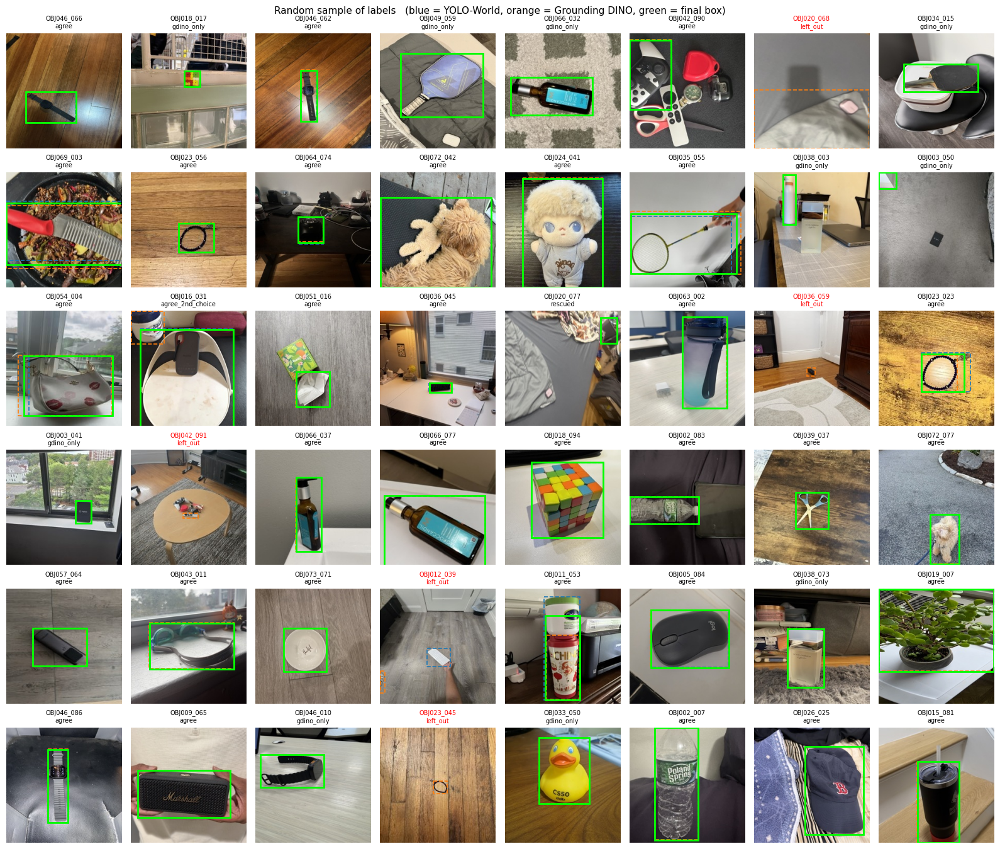

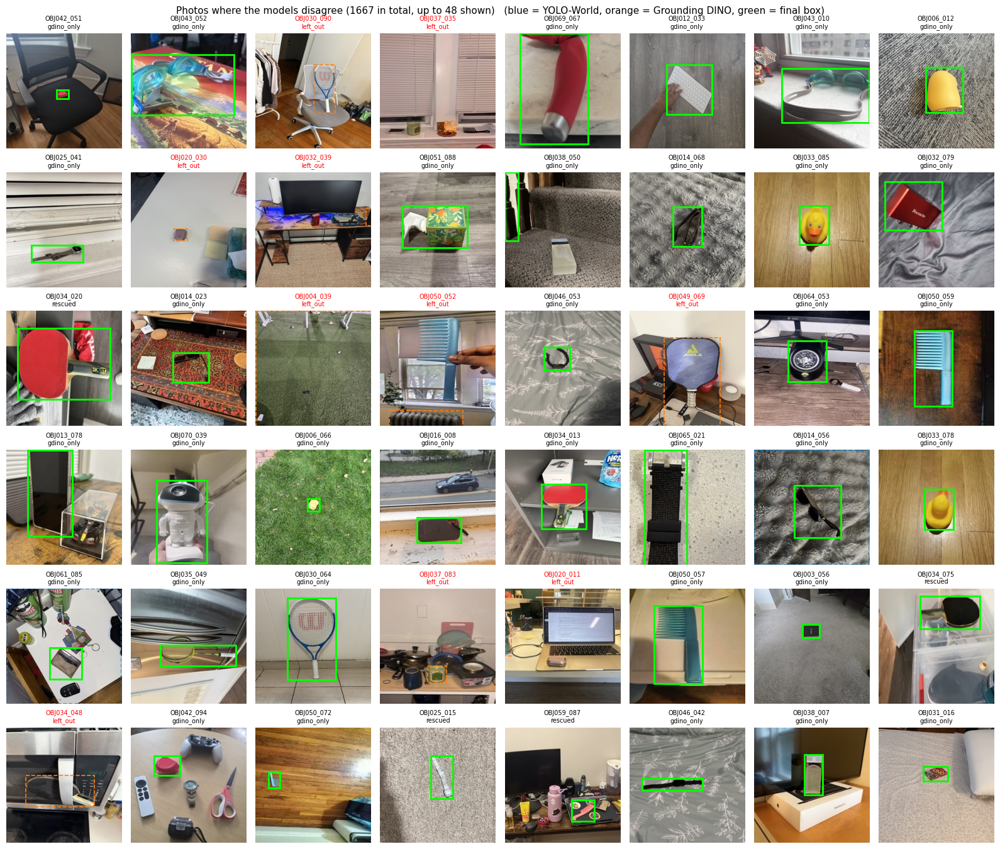

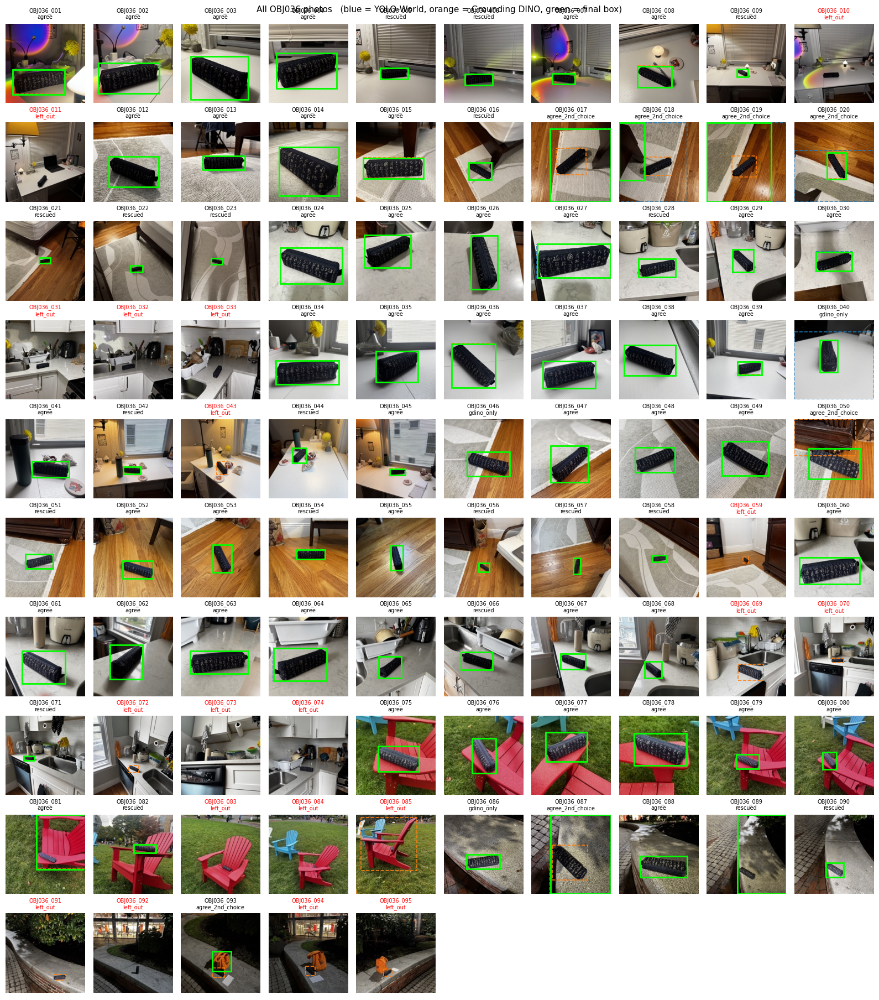

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def show_label_check(stems, title, fname, cols=8, size=2.0):
    stems = list(stems)
    if not stems:
        print("nothing to show:", title)
        return
    rows = (len(stems) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.15), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, stem in zip(axes.flat, stems):
        r = boxes.loc[stem]
        ax.imshow(Image.open(r.photo))
        for cands, color in [(yw_raw.get(stem, [])[:1], "tab:blue"), (gd_raw.get(stem, [])[:1], "tab:orange")]:
            for x1, y1, x2, y2, _ in cands:
                ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.2, ls="--"))
        if r.used:
            ax.add_patch(patches.Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False, ec="lime", lw=2))
        ax.set_title(f"{stem}\n{r.status}", fontsize=7, color="black" if r.used else "red")
    fig.suptitle(f"{title}   (blue = YOLO-World, orange = Grounding DINO, green = final box)", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/{fname}", dpi=110)
    plt.show()


show_label_check(boxes.sample(min(48, len(boxes)), random_state=SEED).stem, "Random sample of labels", "label_check_random.png")
not_agree = boxes[~boxes.status.isin(["agree", "agree_2nd_choice"])]
show_label_check(not_agree.sample(min(48, len(not_agree)), random_state=SEED).stem if len(not_agree) else [],
                 f"Photos where the models disagree ({len(not_agree)} in total, up to 48 shown)", "label_check_disagree.png")
show_label_check(boxes[boxes.obj_id == FOCUS_ID].stem, f"All {FOCUS_ID} photos", f"label_check_{FOCUS_ID}.png", cols=10, size=1.6)

## 6. Multi-object grid images

> **Note (changed):** replaces the version 1 generator (2–5 photos pasted on a background). Following the
> instructors' table:
>
> | Grid | Objects per image | Image size |
> |---|---|---|
> | 2×2 | 4 | 448 × 448 |
> | 3×3 | 9 | 672 × 672 |
> | 4×4 | 16 | 896 × 896 |
> | 5×4 | 20 | 1120 × 896 |
> | 5×5 | 25 | 1120 × 1120 |
>
> * 800 train / 150 val / 150 test grids, with the five sizes in equal numbers in every split.
> * **Train grids use only train photos, val only val photos, test only test photos** (checked below).
> * Photos are dealt from a shuffled deck, so each photo is used about equally often and never twice in one grid.
> * **Augmentation (train only):** each tile is randomly flipped (as in version 1, now with the box flipped too) and
>   gets random brightness, contrast and colour (±25%). YOLOv8 adds its own augmentation during training.
> * Labels are written in YOLO format (`class x_center y_center width height`, normalised by the grid size).
>   A zip copy of the grid dataset is saved to our Drive.

In [ ]:
t0 = time.time()
lab = boxes[boxes.used]
BUILD_CFG = dict(grids=GRID_SIZES, n=N_GRIDS, seeds=GRID_SEEDS, classes=class_names,
                 labels=hashlib.md5(lab[["stem", "split", "x1", "y1", "x2", "y2"]].round(1).to_csv().encode()).hexdigest())


def augment_tile(im, box, rng):
    if rng.random() < 0.5:   # horizontal flip, box flipped with it
        im = ImageOps.mirror(im)
        box = [TILE - box[2], box[1], TILE - box[0], box[3]]
    for enhance in (ImageEnhance.Brightness, ImageEnhance.Contrast, ImageEnhance.Color):
        im = enhance(im).enhance(rng.uniform(0.75, 1.25))
    return im, box


def make_grid(stems, cols, rows, rng=None):
    canvas = Image.new("RGB", (cols * TILE, rows * TILE))
    objs = []
    for k, stem in enumerate(stems):
        r = lab.loc[stem]
        im, box = Image.open(r.photo).convert("RGB"), [r.x1, r.y1, r.x2, r.y2]
        if rng is not None:
            im, box = augment_tile(im, box, rng)
        ox, oy = (k % cols) * TILE, (k // cols) * TILE
        canvas.paste(im, (ox, oy))
        objs.append((class_names.index(r.obj_id), box[0] + ox, box[1] + oy, box[2] + ox, box[3] + oy))
    return canvas, objs


def make_split(name, n_images, seed):
    rng = np.random.default_rng(seed)
    img_dir, lbl_dir = f"{YOLO_DIR}/images/{name}", f"{YOLO_DIR}/labels/{name}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    pool, deck, manifest = list(lab.stem[lab.split == name]), [], []
    for k in range(n_images):
        cols, rows = GRID_SIZES[k % len(GRID_SIZES)]
        need = cols * rows
        assert len(pool) >= need, f"{name}: only {len(pool)} photos for a {cols}x{rows} grid"
        if len(deck) < need:
            deck += [pool[i] for i in rng.permutation(len(pool))]
        stems, later = [], []
        while len(stems) < need:   # never the same photo twice in one grid
            s = deck.pop(0)
            (later if s in stems else stems).append(s)
        deck = later + deck
        img, objs = make_grid(stems, cols, rows, rng if name == "train" else None)
        W, H = img.size
        fname = f"{name}_{k:05d}_{cols}x{rows}"
        img.save(f"{img_dir}/{fname}.jpg", quality=95)
        with open(f"{lbl_dir}/{fname}.txt", "w") as f:
            f.write("".join(f"{c} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}\n"
                            for c, x1, y1, x2, y2 in objs))
        manifest.append(dict(grid=fname, split=name, size=f"{cols}x{rows}", width=W, height=H, n_objects=need, stems=";".join(stems)))
    print(f"{name}: {n_images} images created")
    return manifest


def write_yaml(path, val):
    with open(path, "w") as f:
        f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: {val}\ntest: images/test\nnames:\n")
        for i, n in enumerate(class_names):
            f.write(f"  {i}: {n}\n")


cfg_file = f"{YOLO_DIR}/build_config.json"
if os.path.exists(cfg_file) and json.load(open(cfg_file)) == json.loads(json.dumps(BUILD_CFG)):
    print("grid images already built")
else:
    shutil.rmtree(YOLO_DIR, ignore_errors=True)
    manifest = []
    for name in ["train", "val", "test"]:
        manifest += make_split(name, N_GRIDS[name], GRID_SEEDS[name])
    man = pd.DataFrame(manifest)
    man.to_csv(f"{YOLO_DIR}/grids_manifest.csv", index=False)
    write_yaml(f"{YOLO_DIR}/data.yaml", "images/val")   # settings file that YOLOv8 reads
    for size in man["size"].unique():   # one test list per grid size, for the per-size results
        with open(f"{YOLO_DIR}/test_{size}.txt", "w") as f:
            f.write("".join(f"{YOLO_DIR}/images/test/{g}.jpg\n" for g in man.grid[(man.split == "test") & (man["size"] == size)]))
        write_yaml(f"{YOLO_DIR}/data_test_{size}.yaml", f"test_{size}.txt")
    json.dump(BUILD_CFG, open(cfg_file, "w"))
    shutil.make_archive(f"{OUT_DIR}/grid_dataset", "zip", YOLO_DIR)   # keep a copy in our own Drive
man = pd.read_csv(f"{YOLO_DIR}/grids_manifest.csv")

used = {s: set(";".join(man.stems[man.split == s]).split(";")) for s in ["train", "val", "test"]}
assert not (used["train"] & used["val"] or used["train"] & used["test"] or used["val"] & used["test"])
print("check passed: train, val and test grids use different photos")
display(man.groupby(["size", "split"]).agg(images=("grid", "count"), objects=("n_objects", "sum")).unstack())
print(open(f"{YOLO_DIR}/labels/train/{man.grid[0]}.txt").read())
TIMES["grids"] = (time.time() - t0) / 60

### 6.1 Example grid images with their labels

> **Note (changed):** same idea as version 1's `show_with_boxes`. It now reads the image size from the file,
> because grids have five different sizes. One example per grid size.

In [ ]:
def grid_path(name):
    return f"{YOLO_DIR}/images/{name.split('_')[0]}/{name}.jpg"


def read_gt(img_path):
    # YOLO label file -> list of (class, x1, y1, x2, y2) in pixels
    W, H = Image.open(img_path).size
    out = []
    for line in open(img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"):
        c, cx, cy, w, h = map(float, line.split())
        out.append((int(c), (cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H))
    return out


def show_with_boxes(name, ax):
    path = grid_path(name)
    ax.imshow(Image.open(path))
    for c, x1, y1, x2, y2 in read_gt(path):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.5))
        ax.text(x1, y1 - 3, class_names[c], color="white", fontsize=6, bbox=dict(facecolor="red", pad=1))
    ax.axis("off")
    ax.set_title(name)


examples = [man.grid[(man.split == "train") & (man["size"] == f"{c}x{r}")].iloc[0] for c, r in GRID_SIZES]
fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5.4))
for ax, name in zip(np.atleast_1d(axes), examples):
    show_with_boxes(name, ax)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/grid_examples.png", dpi=110)
plt.show()

## 7. Train YOLOv8s (transfer learning)

> **Note (changed):** same model as version 1. **YOLOv8s pretrained on COCO** (11 M parameters) is fine-tuned on
> our grids, and its detection head is replaced for our 73 Object IDs. Changes:
> * `imgsz=1120` (instructor tip). At 640, a 5×5 grid would be shrunk and each object would be only ~128 px wide.
> * `batch=8` (instructor tip for Colab; lower it if the GPU runs out of memory).
> * Grid images are cached in RAM to speed up training.
> * Checkpoints are written to Drive after every epoch. If Colab disconnects, *Run all* again and training **resumes**
>   from `last.pt`.
> * The best epoch is chosen on the **validation** grids. The test grids are only used for the final results.

In [13]:
from ultralytics import YOLO

t0 = time.time()
RUN_DIR = f"{OUT_DIR}/runs/{RUN_NAME}"
LAST, BEST, DONE = f"{RUN_DIR}/weights/last.pt", f"{RUN_DIR}/weights/best.pt", f"{RUN_DIR}/done.json"

if os.path.exists(DONE):
    print("training already finished:", json.load(open(DONE)))
else:
    if os.path.exists(LAST):
        print("resuming from", LAST)
        try:
            YOLO(LAST).train(resume=True)
        except AssertionError as e:   # last.pt belongs to a finished run
            print(e)
    else:
        model = YOLO(DET_WEIGHTS)   # small YOLOv8 model, pretrained on COCO
        results = model.train(
            data=f"{YOLO_DIR}/data.yaml",
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            patience=PATIENCE,    # stop early if validation results stop improving for 15 epochs
            seed=SEED,
            cache="ram" if GPU else False,
            device=DEVICE,
            project=f"{OUT_DIR}/runs",
            name=RUN_NAME,
            exist_ok=True,
        )
    res = pd.read_csv(f"{RUN_DIR}/results.csv")
    res.columns = res.columns.str.strip()
    json.dump(dict(epochs_run=len(res), train_min=round(float(res["time"].iloc[-1]) / 60, 1) if "time" in res else None,
                   best_val_mAP50=round(float(res["metrics/mAP50(B)"].max()), 4)), open(DONE, "w"))
    print(json.load(open(DONE)))
TIMES["train"] = (time.time() - t0) / 60

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1120, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_grid, nbs=64, nms=None, opset=None, optimize=False, opt

## 8. Training curves and validation confusion matrix

> **Note (new):** Ultralytics already saves these figures in the run folder. Version 1's report said they did not
> exist, but they did. Here they are shown and copied to `week2_results/figures/` for the report.

In [ ]:
for fname, title in [("results.png", "Training curves (losses, precision, recall, mAP per epoch)"),
                     ("confusion_matrix_normalized.png", "Validation confusion matrix (normalised)")]:
    path = f"{RUN_DIR}/{fname}"
    if os.path.exists(path):
        shutil.copy(path, f"{OUT_DIR}/figures/train_{fname}")
        plt.figure(figsize=(16, 9) if fname == "results.png" else (14, 12))
        plt.imshow(plt.imread(path)); plt.axis("off"); plt.title(title)
        plt.show()
    else:
        print("not found:", path)

## 9. Test results

> **Note (changed):** the test call and the printed summary are the same as in version 1, plus:
> * the same metrics **per grid size** (2×2 … 5×5),
> * the metrics **per Object ID**, with our own object OBJ036 and the 10 weakest Object IDs,
> * the test confusion matrix.
>
> Precision and recall from Ultralytics are measured at the confidence threshold with the best F1 score.
> Because the boxes now surround the object instead of the whole photo, **mAP@0.5:0.95 is now expected to be lower than
> mAP@0.5**. In version 1 the two values were identical.

In [ ]:
t0 = time.time()
best_model = YOLO(BEST)
VAL_KW = dict(imgsz=IMGSZ, batch=BATCH, device=DEVICE, project=f"{OUT_DIR}/runs", exist_ok=True)

test_metrics = best_model.val(data=f"{YOLO_DIR}/data.yaml", split="test", name="test_eval", **VAL_KW)

print("\nTEST RESULTS")
print("Precision:", round(test_metrics.box.mp, 3))
print("Recall:", round(test_metrics.box.mr, 3))
print("mAP50:", round(test_metrics.box.map50, 3))
print("mAP50-95:", round(test_metrics.box.map, 3))


def box_metrics(m):
    return dict(precision=round(float(m.box.mp), 3), recall=round(float(m.box.mr), 3),
                mAP50=round(float(m.box.map50), 3), mAP50_95=round(float(m.box.map), 3))


rows = [dict(grid="all test grids", images=int((man.split == "test").sum()),
             objects=int(man.n_objects[man.split == "test"].sum()), **box_metrics(test_metrics))]
for c, r in GRID_SIZES:
    m = best_model.val(data=f"{YOLO_DIR}/data_test_{c}x{r}.yaml", split="val", name=f"test_{c}x{r}", plots=False, verbose=False, **VAL_KW)
    sel = (man.split == "test") & (man["size"] == f"{c}x{r}")
    rows.append(dict(grid=f"{c}x{r} ({c * TILE}x{r * TILE})", images=int(sel.sum()), objects=int(man.n_objects[sel].sum()), **box_metrics(m)))
test_by_grid = pd.DataFrame(rows)
test_by_grid.to_csv(f"{OUT_DIR}/test_metrics_by_grid_size.csv", index=False)
print("\nTest results per grid size:")
display(test_by_grid)

per_class = pd.DataFrame([dict(obj_id=class_names[c], **dict(zip(["precision", "recall", "AP50", "AP50_95"],
                                                                map(float, test_metrics.box.class_result(i)))))
                          for i, c in enumerate(test_metrics.box.ap_class_index)]).round(3)
per_class.to_csv(f"{OUT_DIR}/test_metrics_per_object.csv", index=False)
print(f"{FOCUS_ID} (our object):")
display(per_class[per_class.obj_id == FOCUS_ID])
print("10 weakest Object IDs (AP50):")
display(per_class.sort_values("AP50").head(10))

In [ ]:
path = f"{OUT_DIR}/runs/test_eval/confusion_matrix_normalized.png"
if os.path.exists(path):
    shutil.copy(path, f"{OUT_DIR}/figures/test_confusion_matrix_normalized.png")
    plt.figure(figsize=(14, 12)); plt.imshow(plt.imread(path)); plt.axis("off"); plt.title("Test confusion matrix (normalised)")
    plt.show()

## 10. Detect, identify and locate the objects in an image

> **Note (changed):** `detect_objects` works as in version 1. It prints every object's **ID, confidence and box**
> (x1, y1, x2, y2 in pixels) and now also the **grid row / column**. It also returns the table and can draw the
> prediction next to the true labels: white dashed = true box, green = correct detection, red = wrong ID or badly
> placed box. The thick box is OBJ036.
>
> `true_labels` prints the true objects of a grid, as in version 1.

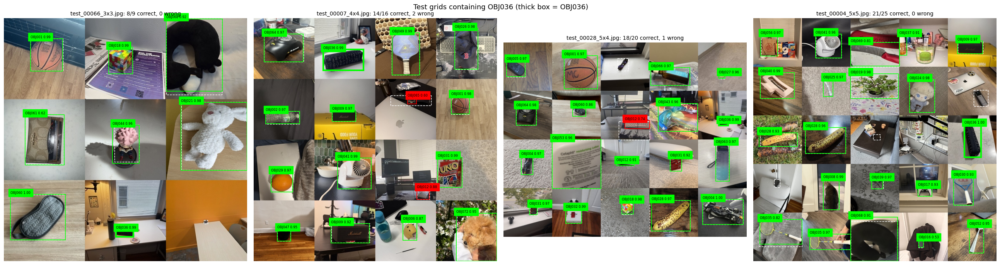

Image: test_00004_5x5.jpg | objects found: 21


,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ056,0.97,34,75,111,173,1,1
1,OBJ041,0.96,287,72,405,183,1,2
2,OBJ069,0.81,448,112,672,220,1,3
3,OBJ037,0.91,672,75,707,171,1,4
4,OBJ009,0.97,940,104,1056,164,1,5
5,OBJ040,0.99,32,251,189,369,2,1
6,OBJ025,0.97,322,279,366,361,2,2
7,OBJ019,0.98,448,255,668,370,2,3
8,OBJ024,0.98,719,282,835,434,2,4
9,OBJ028,0.93,27,528,202,590,3,1


TRUE objects in test_00004_5x5:


,object_id,x1,y1,x2,y2,row,col
0,OBJ056,34,76,112,174,1,1
1,OBJ041,288,72,405,183,1,2
2,OBJ069,448,110,672,223,1,3
3,OBJ037,672,74,706,170,1,4
4,OBJ009,941,105,1057,164,1,5
5,OBJ040,32,251,189,370,2,1
6,OBJ025,322,279,365,361,2,2
7,OBJ019,450,254,663,367,2,3
8,OBJ024,718,282,835,434,2,4
9,OBJ057,1014,330,1081,406,2,5


OBJ036 found at: [[3.0, 5.0, 971.0, 488.0, 1048.0, 640.0, 1.0]]


In [17]:
def detect_objects(image_path, conf=CONF, ax=None, verbose=True):
    result = best_model.predict(image_path, imgsz=IMGSZ, conf=conf, device=DEVICE, verbose=False)[0]
    rows = []
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        rows.append(dict(object_id=class_names[int(box.cls[0])], confidence=round(float(box.conf[0]), 2),
                         x1=round(x1), y1=round(y1), x2=round(x2), y2=round(y2),
                         row=int((y1 + y2) / 2 // TILE) + 1, col=int((x1 + x2) / 2 // TILE) + 1))
    det = pd.DataFrame(rows, columns=["object_id", "confidence", "x1", "y1", "x2", "y2", "row", "col"])
    det = det.sort_values(["row", "col"]).reset_index(drop=True)
    if verbose:
        print(f"Image: {os.path.basename(image_path)} | objects found: {len(det)}")
        display(det)
    if ax is not None:
        gt = read_gt(image_path) if "/images/" in image_path else None
        ax.imshow(Image.open(image_path)); ax.axis("off")
        for c, x1, y1, x2, y2 in gt or []:
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white", lw=1, ls="--"))
        n_ok = 0
        for d in det.itertuples():
            ok = gt is None or any(class_names[c] == d.object_id and iou([d.x1, d.y1, d.x2, d.y2], b) >= 0.5 for c, *b in gt)
            n_ok += ok
            color = "lime" if ok else "red"
            ax.add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, ec=color,
                                           lw=3 if d.object_id == FOCUS_ID else 1.2))
            ax.text(d.x1, d.y1, f"{d.object_id} {d.confidence:.2f}", fontsize=6, color="black", backgroundcolor=color, va="bottom")
        if gt is not None:
            ax.set_title(f"{os.path.basename(image_path)}: {n_ok}/{len(gt)} correct, {len(det) - n_ok} wrong", fontsize=10)
    return det


def true_labels(name):
    print(f"TRUE objects in {name}:")
    gt = pd.DataFrame([dict(object_id=class_names[c], x1=round(x1), y1=round(y1), x2=round(x2), y2=round(y2),
                            row=int((y1 + y2) / 2 // TILE) + 1, col=int((x1 + x2) / 2 // TILE) + 1)
                       for c, x1, y1, x2, y2 in read_gt(grid_path(name))])
    display(gt.sort_values(["row", "col"]).reset_index(drop=True))


# example: test grids that contain OBJ036, one per grid size
focus_stems = set(lab.stem[lab.obj_id == FOCUS_ID])
test_grids = man[man.split == "test"]
has_focus = test_grids[test_grids.stems.apply(lambda s: bool(focus_stems & set(s.split(";"))))]
picks = [has_focus.grid[has_focus["size"] == f"{c}x{r}"].iloc[0] for c, r in GRID_SIZES if (has_focus["size"] == f"{c}x{r}").any()]
picks = picks[-4:] if picks else list(test_grids.grid[:4])
fig, axes = plt.subplots(1, len(picks), figsize=(6.5 * len(picks), 7))
for ax, name in zip(np.atleast_1d(axes), picks):
    detect_objects(grid_path(name), ax=ax, verbose=False)
plt.suptitle(f"Test grids containing {FOCUS_ID} (thick box = {FOCUS_ID})", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/example_detections.png", dpi=120)
plt.show()

det = detect_objects(grid_path(picks[-1]))
true_labels(picks[-1])
print(f"{FOCUS_ID} found at:", det.loc[det.object_id == FOCUS_ID, ["row", "col", "x1", "y1", "x2", "y2", "confidence"]].values.tolist())

### 10.1 All test grids at confidence 0.5, and error analysis

> **Note (new):** version 1 showed one example. This cell runs `detect_objects` on **every test grid** at the
> same threshold (0.5). A detection is correct when the Object ID is right and the box overlaps the true box with
> IoU ≥ 0.5. It reports:
> * correct / wrong / missed objects and the number of grids where **every** object was found with nothing extra,
>   per grid size,
> * which Object IDs are missed most, and which IDs are confused with which,
> * a figure with examples of missed objects, as input for the report's error analysis.

In [ ]:
def match(pred, gt, conf):
    # greedy by confidence: correct if same Object ID and IoU >= 0.5 with a true box that is not matched yet
    cls, cf, xy = pred
    keep = [i for i in np.argsort(cf)[::-1] if cf[i] >= conf]
    taken, ok = set(), []
    for i in keep:
        best, bj = 0.5, None
        for j, (c, *b) in enumerate(gt):
            if j not in taken and c == cls[i] and iou(xy[i], b) >= best:
                best, bj = iou(xy[i], b), j
        if bj is not None:
            taken.add(bj)
        ok.append(bj is not None)
    return keep, ok, taken


test_paths = [grid_path(g) for g in test_grids.grid]
preds = {}
for i in range(0, len(test_paths), 8):   # 8 grids at a time (1120 px) to stay within GPU memory
    batch = test_paths[i:i + 8]
    for p, r in zip(batch, best_model.predict(batch, imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False)):
        preds[p] = (r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())

per_img, errors = [], []
for p, pred in preds.items():
    gt = read_gt(p)
    keep, ok, taken = match(pred, gt, CONF)
    per_img.append(dict(size=os.path.basename(p)[:-4].split("_")[-1], objects=len(gt), correct=sum(ok),
                        wrong_or_extra=len(ok) - sum(ok), missed=len(gt) - len(taken)))
    cls, cf, xy = pred
    for j, (c, *b) in enumerate(gt):
        if j not in taken:
            o, i = max(((iou(xy[i], b), i) for i in keep), default=(0, None))
            errors.append(dict(path=p, box=b, true_id=class_names[c],
                               predicted=f"{class_names[cls[i]]} ({cf[i]:.2f})" if o >= 0.5 else "not detected",
                               predicted_id=class_names[cls[i]] if o >= 0.5 else None))
per_img = pd.DataFrame(per_img)
per_img["all_correct"] = (per_img.wrong_or_extra == 0) & (per_img.missed == 0)
by_size = per_img.groupby("size").agg(images=("objects", "size"), objects=("objects", "sum"), correct=("correct", "sum"),
                                      wrong_or_extra=("wrong_or_extra", "sum"), missed=("missed", "sum"),
                                      grids_all_correct=("all_correct", "sum"))
by_size.loc["all"] = by_size.sum()
by_size["precision"] = (by_size.correct / (by_size.correct + by_size.wrong_or_extra).clip(lower=1)).round(3)
by_size["recall"] = (by_size.correct / by_size.objects).round(3)
by_size.to_csv(f"{OUT_DIR}/test_detection_at_conf{CONF}.csv")
print(f"Test grids at confidence {CONF}:")
display(by_size)

errors = pd.DataFrame(errors, columns=["path", "box", "true_id", "predicted", "predicted_id"])
print("Object IDs with the most missed or wrongly identified test objects:")
display(errors.true_id.value_counts().head(10).rename("errors"))
print("Most frequent confusions (true -> predicted):")
display(errors.dropna(subset=["predicted_id"]).groupby(["true_id", "predicted_id"]).size().sort_values(ascending=False).head(10).rename("count"))

n = min(16, len(errors))
if n:
    show = errors.sample(n, random_state=SEED)
    fig, axes = plt.subplots((n + 7) // 8, 8, figsize=(16, 2.8 * ((n + 7) // 8)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, e in zip(axes.flat, show.itertuples()):
        x1, y1, x2, y2 = e.box
        col, row = int((x1 + x2) / 2 // TILE), int((y1 + y2) / 2 // TILE)
        ax.imshow(Image.open(e.path).crop((col * TILE, row * TILE, (col + 1) * TILE, (row + 1) * TILE)))
        ax.add_patch(patches.Rectangle((x1 - col * TILE, y1 - row * TILE), x2 - x1, y2 - y1, fill=False, ec="white", ls="--"))
        ax.set_title(f"true {e.true_id}\npred: {e.predicted}", fontsize=8, color="red")
    plt.suptitle(f"Examples of test objects that were missed or wrongly identified (confidence {CONF})")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/test_errors.png", dpi=110)
    plt.show()
TIMES["evaluate"] = (time.time() - t0) / 60

## 11. Summary for the report

> **Note (new):** collects every number the instructors asked for: Object IDs, grid sizes, how the labels were made
> and checked, photos left out per Object ID, metrics, training details and timings. It is saved as
> `week2_results/week2_summary.json`. The best model is copied to `week2_results/best_yolov8s_grid.pt`.

In [19]:
shutil.copy(BEST, f"{OUT_DIR}/best_{RUN_NAME}.pt")
TIMES["total_this_session"] = (time.time() - T_START) / 60
summary = dict(
    object_ids=f"{len(class_names)} IDs ({class_names[0]}–{class_names[-1]})",
    grid_sizes=[f"{c}x{r} ({c * TILE}x{r * TILE})" for c, r in GRID_SIZES],
    photos=dict(unique=len(photos),
                removed_before_split={k: int(v) for k, v in removed.reason.str.replace(r" of OBJ.*|:.*", "", regex=True).value_counts().items()},
                **{k: int(v) for k, v in photos.split.value_counts().items()}),
    labels=LABEL_STATS,
    left_out_per_object={k: int(v) for k, v in per_obj.left_out[per_obj.left_out > 0].items()},
    grids={s: int((man.split == s).sum()) for s in ["train", "val", "test"]},
    objects_in_grids={s: int(man.n_objects[man.split == s].sum()) for s in ["train", "val", "test"]},
    training=dict(model=DET_WEIGHTS, imgsz=IMGSZ, batch=BATCH, max_epochs=EPOCHS, patience=PATIENCE, **json.load(open(DONE))),
    test=test_by_grid.iloc[0][["precision", "recall", "mAP50", "mAP50_95"]].to_dict(),
    test_by_grid=test_by_grid.set_index("grid")[["precision", "recall", "mAP50", "mAP50_95"]].to_dict("index"),
    test_at_conf=dict(conf=CONF, **{k: (int(v) if k not in ("precision", "recall") else float(v)) for k, v in by_size.loc["all"].items()}),
    focus_object=per_class[per_class.obj_id == FOCUS_ID].to_dict("records"),
    minutes={k: round(v, 1) for k, v in TIMES.items()},
)
json.dump(summary, open(f"{OUT_DIR}/week2_summary.json", "w"), indent=1, default=str)
print(json.dumps(summary, indent=1, default=str))

{
 "object_ids": "73 IDs (OBJ001\u2013OBJ073)",
 "grid_sizes": [
  "2x2 (448x448)",
  "3x3 (672x672)",
  "4x4 (896x896)",
  "5x4 (1120x896)",
  "5x5 (1120x1120)"
 ],
 "photos": {
  "unique": 6947,
  "removed_before_split": {
   "exact duplicate": 16,
   "excluded": 1
  },
  "train": 4862,
  "test": 1043,
  "val": 1042
 },
 "labels": {
  "photos": 6947,
  "used": 6598,
  "left_out": 349,
  "models_agree": 5280,
  "agree_pct": 76.0,
  "mean_iou_when_agree": 0.944,
  "status_counts": {
   "agree": 4712,
   "gdino_only": 1180,
   "agree_2nd_choice": 568,
   "left_out": 349,
   "rescued": 130,
   "yoloworld_only": 8
  }
 },
 "left_out_per_object": {
  "OBJ003": 8,
  "OBJ004": 6,
  "OBJ007": 1,
  "OBJ009": 1,
  "OBJ012": 8,
  "OBJ013": 9,
  "OBJ014": 11,
  "OBJ017": 1,
  "OBJ020": 19,
  "OBJ023": 7,
  "OBJ025": 18,
  "OBJ026": 1,
  "OBJ029": 1,
  "OBJ030": 6,
  "OBJ031": 2,
  "OBJ032": 11,
  "OBJ033": 8,
  "OBJ034": 19,
  "OBJ036": 19,
  "OBJ037": 19,
  "OBJ038": 2,
  "OBJ040": 15,
  "OBJ041